# DS 6021 Lab 6: Missing Data, Regularization, Logistic Regression


# Part 1: Missing Data and Imputation


Notebook reviewed: `missing_data_and_imputation.ipynb`, from the class repository (`in_class_notebooks/`).


### Question 1


##### Part a


The reason the cell is erroring is that some of the predictor values are NaN and sklearn does not remove entries from the data on its own; it just validates.


##### Part b


It tells us that the predictor variables are mostly uncorrelated with the worst being age and sysBP at 0.39. No predictor has a strong correlation with totChol, with age being the highest at 0.26.


##### Part c


The deletion was random and not based on any of the predictors, so it was missing completely at random (MCAR).


##### Part d


While most of the coefficients don't change much and there is no significant difference between them, the variation in the second model with the deleted data points is much higher.


##### Part e


That is because if you are actually missing the data you wouldn't be able to calculate the mean including the missing values, so only the mean without using the missing data is actually relevant.


# Part 2: Regularization


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import ElasticNetCV, LassoCV, LinearRegression, RidgeCV, lasso_path
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

auto = pd.read_csv("Auto.csv", na_values="?").dropna().reset_index(drop=True)

num = ["displacement", "horsepower", "weight", "acceleration", "year"]
X = auto[num]
y = auto["mpg"]

SEED = 200
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

alphas = np.logspace(-3, 3, 100)
auto.shape


(392, 9)

### Question 1


##### Part a


In [2]:
ols_all = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)

short = ["horsepower", "weight", "year"]
ols_short = make_pipeline(StandardScaler(), LinearRegression()).fit(X[short], y)

coef_table = pd.DataFrame(index=num)
coef_table["OLS (all 5)"] = ols_all.named_steps["linearregression"].coef_
coef_table["OLS (hp, wt, year)"] = pd.Series(
    ols_short.named_steps["linearregression"].coef_, index=short
)
coef_table.round(4).replace(-0.0, 0.0)


,OLS (all 5),"OLS (hp, wt, year)"
displacement,0.2907,NaN
horsepower,0.0392,-0.1922
weight,-5.8312,-5.4697
acceleration,0.2489,NaN
year,2.7744,2.7545


##### Part b


Standardization is required for ridge and lasso regression since the penalty is based on the coefficient magnitude, and without standardizing the penalty would be applied unevenly. For OLS the model fit does not change since we are only rescaling the predictors, which rescales the coefficients but does not change the actual prediction.


### Question 2


##### Part a


In [3]:
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=cv)).fit(X, y)


##### Part b


In [4]:
print("Ridge alpha:", ridge.named_steps["ridgecv"].alpha_)
coef_table["Ridge"] = ridge.named_steps["ridgecv"].coef_
coef_table.round(4).replace(-0.0, 0.0)


Ridge alpha: 1.232846739442066


,OLS (all 5),"OLS (hp, wt, year)",Ridge
displacement,0.2907,NaN,0.1473
horsepower,0.0392,-0.1922,-0.0444
weight,-5.8312,-5.4697,-5.6340
acceleration,0.2489,NaN,0.2011
year,2.7744,2.7545,2.7527


##### Part c


No coefficients went to zero; they just moved towards zero. For ridge, coefficients only approach zero, lasso is where they will go to zero. In absolute terms the largest change was weight at +0.1972. Displacement almost halved and horsepower went from positive to negative.

### Question 3


##### Part a


In [5]:
lasso = make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=cv)).fit(X, y)


##### Part b


In [6]:
print("Lasso alpha:", lasso.named_steps["lassocv"].alpha_)
coef_table["Lasso"] = lasso.named_steps["lassocv"].coef_
coef_table.round(4).replace(-0.0, 0.0)


Lasso alpha: 0.049770235643321115


,OLS (all 5),"OLS (hp, wt, year)",Ridge,Lasso
displacement,0.2907,NaN,0.1473,0.0000
horsepower,0.0392,-0.1922,-0.0444,0.0000
weight,-5.8312,-5.4697,-5.6340,-5.5324
acceleration,0.2489,NaN,0.2011,0.1542
year,2.7744,2.7545,2.7527,2.7207


The lasso model dropped displacement and horsepower, leaving their coefficients at exactly zero.


##### Part c


The reason we would trust Lasso more than Forward/Backward is because Lasso dynamically removes coefficients based on the penalty, while for Forward/Backward you set a k beforehand to decide how many coefficients to keep. Forward/Backward also never reevaluates previous removals, so a variable removed at a previous k can never be used in the next k even if it would be a better fit. Lasso is limited by its bias towards zero for the coefficients and will always lower coefficients to zero as the penalty increases, so it does not perform well when there are many predictors with small effects. Lasso is also somewhat arbitrary in which correlated predictors get dropped, so a different sample or fold could easily keep a different variable set.


### Question 4


##### Part a


In [7]:
enet = make_pipeline(
    StandardScaler(), ElasticNetCV(alphas=alphas, l1_ratio=[0.1, 0.5, 0.9, 1], cv=cv)
).fit(X, y)


##### Part b


In [8]:
enet_model = enet.named_steps["elasticnetcv"]
print("ElasticNet alpha:", enet_model.alpha_, " l1_ratio:", enet_model.l1_ratio_)
coef_table["ElasticNet"] = enet_model.coef_
coef_table.round(4).replace(-0.0, 0.0)


ElasticNet alpha: 0.049770235643321115  l1_ratio: 1.0


,OLS (all 5),"OLS (hp, wt, year)",Ridge,Lasso,ElasticNet
displacement,0.2907,NaN,0.1473,0.0000,0.0000
horsepower,0.0392,-0.1922,-0.0444,0.0000,0.0000
weight,-5.8312,-5.4697,-5.6340,-5.5324,-5.5324
acceleration,0.2489,NaN,0.2011,0.1542,0.1542
year,2.7744,2.7545,2.7527,2.7207,2.7207


l1_ratio is 1.0, so it is using 100% lasso penalty and no ridge, which is also why the coefficients are the same as the lasso model.


##### Part c


All five different models use weight and year. Horsepower is kept by both OLS models, shrunk and sign-flipped by ridge, then zeroed by Lasso and ElasticNet, while acceleration survives in all four models that contain it with a smaller coefficient. Weight and year are the only predictors kept large by every method, so they are the two that matter.


# Part 3: Logistic Regression


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

fram = pd.read_csv("framingham.csv").dropna()
y = fram["TenYearCHD"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

preprocess = ColumnTransformer(transformers=[
    ("binary", "passthrough", ["male"]),
    ("numeric", StandardScaler(), ["numeric"]),
])


### Question 1


##### Part a


In [10]:
chd_rate = y.mean()
print(f"Fraction of patients who developed CHD: {chd_rate:.4f}")


Fraction of patients who developed CHD: 0.1523


##### Part b


In [11]:
print(f"Accuracy of predicting no CHD for everyone: {accuracy_score(y, np.zeros(len(y), dtype=int)):.4f}")


Accuracy of predicting no CHD for everyone: 0.8477


##### Part c


In [12]:
print(f"Log loss of the constant model: {log_loss(y, np.full(len(y), chd_rate)):.4f}")


Log loss of the constant model: 0.4266


### Question 2


##### Part a


In [13]:
preprocess_A = ColumnTransformer(transformers=[
    ("binary", "passthrough", ["male"]),
    ("numeric", StandardScaler(), ["age"]),
])
modelA = Pipeline([("preprocess", preprocess_A), ("model", LogisticRegression())]).fit(
    fram[["male", "age"]], y
)

preprocess_B = ColumnTransformer(transformers=[
    ("binary", "passthrough", ["male"]),
    ("numeric", StandardScaler(), ["cigsPerDay"]),
])
modelB = Pipeline([("preprocess", preprocess_B), ("model", LogisticRegression())]).fit(
    fram[["male", "cigsPerDay"]], y
)


##### Part b


In [14]:
pA = modelA.predict_proba(fram[["male", "age"]])[:, 1]
pB = modelB.predict_proba(fram[["male", "cigsPerDay"]])[:, 1]

print(f"Model A log loss: {log_loss(y, pA):.4f}")
print(f"Model B log loss: {log_loss(y, pB):.4f}")


Model A log loss: 0.3942
Model B log loss: 0.4222


##### Part c


In [15]:
hand_log_loss = -np.mean(y * np.log(pA) + (1 - y) * np.log(1 - pA))
print(f"Hand-computed log loss for Model A: {hand_log_loss:.4f}")
print(f"sklearn log loss for Model A:       {log_loss(y, pA):.4f}")


Hand-computed log loss for Model A: 0.3942
sklearn log loss for Model A:       0.3942


### Question 3


##### Part a


In [16]:
rows = []
for name, pipe, cols in [("Model A", modelA, ["male", "age"]),
                         ("Model B", modelB, ["male", "cigsPerDay"])]:
    res = cross_validate(pipe, fram[cols], y, cv=cv,
                         scoring=["accuracy", "neg_log_loss", "roc_auc"])
    rows.append({
        "model": name,
        "accuracy": res["test_accuracy"].mean(),
        "accuracy sd": res["test_accuracy"].std(),
        "log loss": -res["test_neg_log_loss"].mean(),
        "log loss sd": res["test_neg_log_loss"].std(),
        "roc auc": res["test_roc_auc"].mean(),
        "roc auc sd": res["test_roc_auc"].std(),
    })
pd.DataFrame(rows).round(4)


,model,accuracy,accuracy sd,log loss,log loss sd,roc auc,roc auc sd
0,Model A,0.8480,0.0010,0.3953,0.0134,0.7013,0.0396
1,Model B,0.8477,0.0006,0.4233,0.0023,0.5645,0.0319


##### Part b


The always no baseline has an accuracy of 0.8477 while Model A is 0.848 with an sd of 0.001 and Model B is 0.8477 with an sd of 0.0006, so there is no real difference in the accuracy of either model compared to the always no baseline. This suggests accuracy is not a very good metric for choosing between models, since the always no model would be just as good as both models A and B.


##### Part c


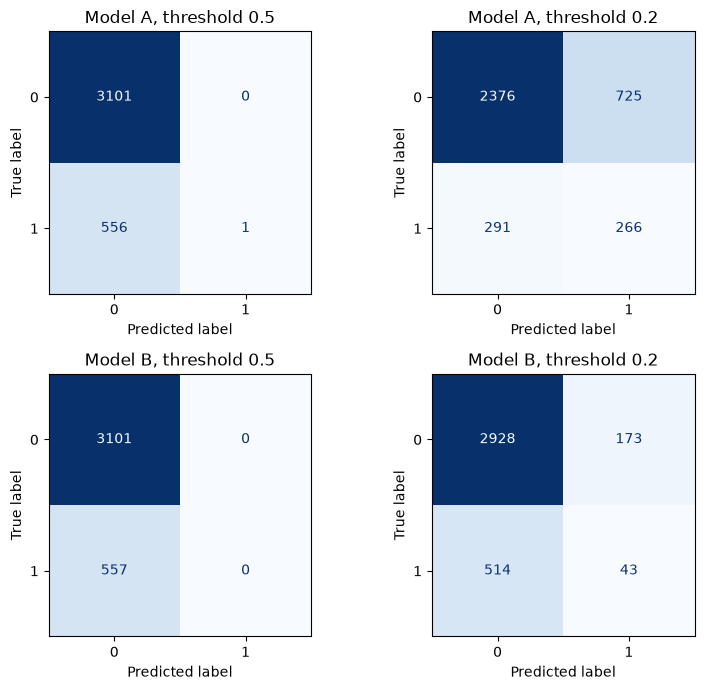

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for row, (name, pipe, cols) in enumerate([("Model A", modelA, ["male", "age"]),
                                          ("Model B", modelB, ["male", "cigsPerDay"])]):
    p_cv = cross_val_predict(pipe, fram[cols], y, cv=cv, method="predict_proba")[:, 1]
    for col, threshold in enumerate([0.5, 0.2]):
        cm = confusion_matrix(y, (p_cv >= threshold).astype(int), labels=pipe.classes_)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipe.classes_)
        disp.plot(ax=axes[row, col], cmap="Blues", colorbar=False)
        axes[row, col].set_title(f"{name}, threshold {threshold}")
plt.tight_layout()
plt.show()


At a threshold of 0.5 both models almost never predict true, so they are basically the same as the always no model. Lowering the threshold to 0.2 makes both models start predicting true, with Model A noticeably more affected by the change.


##### Part d


Model A has a noticeably better log loss at 0.3953, while Model B at 0.4233 is barely better than the baseline of 0.4266. Model A's AUC is 0.7013 against Model B's 0.5645. At the 0.2 threshold Model A produces 291 false negatives while Model B produces 514. Model A does have a higher false positive rate, but given the context of the model, a false negative is much worse than a false positive. Given all of this, Model A is clearly the superior model.


### AI Acknowledgment

I used an AI assistant to help write code for this lab. I checked the outputs myself against the data and the class materials to make sure the code worked correctly. I also used AI to help with spelling and grammar in my written answers. All questions were answered in my own words.
